Week Three - Assignment Graph Visualization 
Yana Rabkova

In [2]:

import urllib.request
import networkx as nx

# Download dataset from Stanford SNAP
url = "https://snap.stanford.edu/data/ca-GrQc.txt.gz"
filename = "ca-GrQc.txt.gz"

urllib.request.urlretrieve(url, filename)

# Load the graph
G = nx.read_edgelist(
    filename,
    comments="#",
    nodetype=int
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())


Nodes: 5242
Edges: 14496


There are 5,242 researchers(nodes) and 14,496 collaborations(edges)

In [3]:

# Check connected components
components = list(nx.connected_components(G))

print("Number of connected components:", len(components))

# Select largest connected component
largest_component = max(components, key=len)
H = G.subgraph(largest_component).copy()

print("Nodes in largest component:", H.number_of_nodes())

# Calculate diameter
diameter = nx.diameter(H)
print("Diameter:", diameter)


Number of connected components: 355
Nodes in largest component: 4158
Diameter: 17


In [5]:

degree_centrality = nx.degree_centrality(G)

top_10 = sorted(
    degree_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 researchers by degree centrality:")
for researcher, centrality in top_10:
    print(f"Researcher {researcher}: {centrality:.4f}")


clustering = nx.average_clustering(G)

print("Average clustering coefficient:", round(clustering, 4))


Top 10 researchers by degree centrality:
Researcher 21012: 0.0155
Researcher 21281: 0.0151
Researcher 22691: 0.0147
Researcher 12365: 0.0147
Researcher 6610: 0.0130
Researcher 9785: 0.0130
Researcher 21508: 0.0128
Researcher 17655: 0.0126
Researcher 2741: 0.0124
Researcher 19423: 0.0120
Average clustering coefficient: 0.5296


In [6]:

from networkx.algorithms.community import louvain_communities

# Detect communities in the largest component
communities = louvain_communities(H, seed=42)

print("Number of communities:", len(communities))

# Display the largest communities
sizes = sorted(
    [len(c) for c in communities],
    reverse=True
)

print("10 largest community sizes:", sizes[:10])


Number of communities: 41
10 largest community sizes: [324, 235, 219, 210, 206, 205, 203, 187, 178, 151]


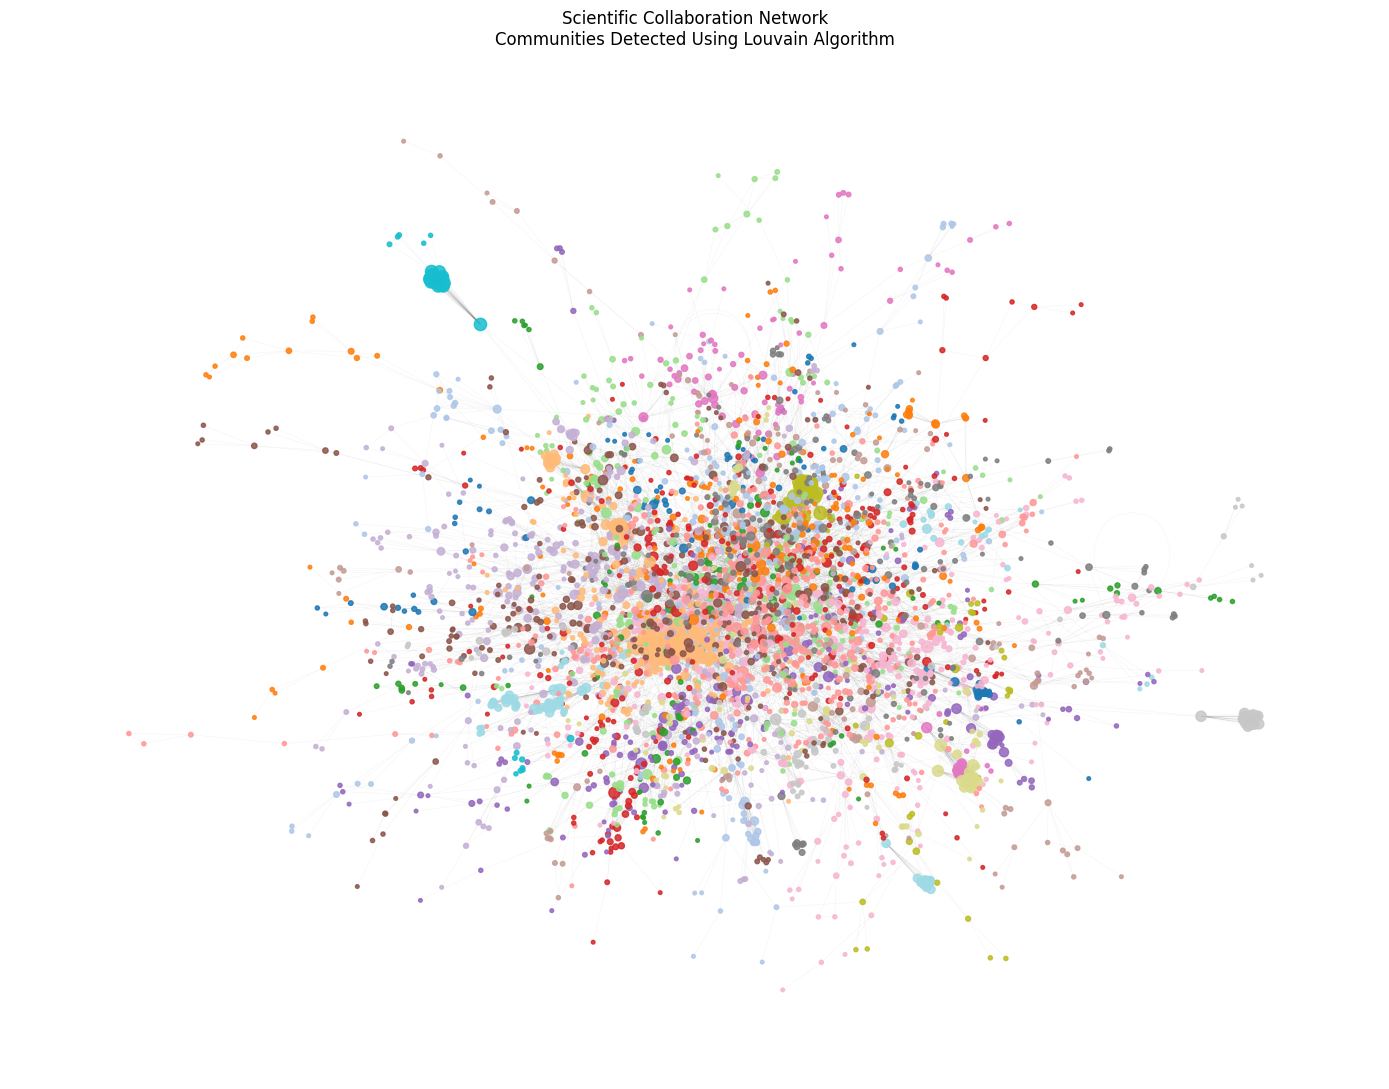

In [7]:

import networkx as nx
import matplotlib.pyplot as plt

# Map each researcher to their community
community_map = {}

for i, community in enumerate(communities):
    for node in community:
        community_map[node] = i

# Layout
pos = nx.spring_layout(H, seed=42, iterations=50)

# Node colors and sizes
node_colors = [
    community_map[node] for node in H.nodes()
]

node_sizes = [
    5 + H.degree(node) * 2
    for node in H.nodes()
]

plt.figure(figsize=(14, 11))

nx.draw_networkx_edges(
    H, pos,
    alpha=0.06,
    width=0.3
)

nx.draw_networkx_nodes(
    H, pos,
    node_color=node_colors,
    node_size=node_sizes,
    cmap=plt.cm.tab20,
    alpha=0.85
)

plt.title(
    "Scientific Collaboration Network\n"
    "Communities Detected Using Louvain Algorithm"
)

plt.axis("off")
plt.tight_layout()
plt.show()


In [8]:

# Create a copy with community attributes
G_export = H.copy()

nx.set_node_attributes(
    G_export,
    community_map,
    "community"
)

# Add degree as a node attribute
degree_map = dict(H.degree())

nx.set_node_attributes(
    G_export,
    degree_map,
    "degree_count"
)

# Export
nx.write_gexf(
    G_export,
    "ca-GrQc_communities.gexf"
)

print("Gephi file exported successfully!")


Gephi file exported successfully!
